# 문서 탐색 (EDA) — 결과 모음

> **Day 6(2026-11-10) 재정리 노트북이다.** 실제 탐색은 벡터 DB 적재 전인 Day 1~3에 했다.
> - 제공 뉴스 탐색: `notebooks/news_selection.ipynb` (Day 1)
> - 댓글 수집 시험: `notebooks/youtube_api_test.ipynb` (Day 1)
> - 댓글 정제 전후 건수: `indexer/clean.py` → `report/evidence/clean_stats.csv` (Day 2)
> - 사례별 반응 비율: `indexer/case_summary.py` → `report/evidence/case_summary.csv` (Day 2)
> - 정부 PDF 쪽별 글자 수: `indexer/parse.py` → `store/docs.db` gov_pages (Day 3)
>
> 이 노트북은 위에서 **이미 저장된 결과만 읽어** 한곳에 모은다. 파일·DB에 쓰지 않는다 (docs.db는 읽기 전용으로 연다).
> 리포트 2-2(EDA)·4-1(정제 전후 건수)의 근거다.

In [1]:
# 경로·한글 글꼴·읽기 전용 DB 연결 준비 (노트북 위치 기준 ../ 가 프로젝트 루트)
import json, sqlite3, unicodedata
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
plt.rcParams["font.family"] = "AppleGothic"          # 맥 기본 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 40)

def find(folder, name):
    """한글 파일명을 NFC로 맞춰 찾음 (맥 NFD 문제)"""
    for p in (ROOT / folder).iterdir():
        if unicodedata.normalize("NFC", p.name) == unicodedata.normalize("NFC", name):
            return p
    raise FileNotFoundError(f"{folder}/{name}")

con = sqlite3.connect(f"file:{ROOT / 'store' / 'docs.db'}?mode=ro", uri=True)
print("docs.db 표:", [r[0] for r in con.execute("select name from sqlite_master where type='table'")])

docs.db 표: ['youtube_comments', 'comment_filter', 'comment_label', 'case_summary', 'gov_docs', 'news_provided', 'gov_pages', 'chunks']


## 1. 댓글 수집·정제 전후 (리포트 4-1)

,before,kept
kind,,
답글,2519,548
최상위,2938,1742
합계,5457,2290


,제외 수
문구 중복,32
채널 주인,137
10자 미만,699
외국어,2299


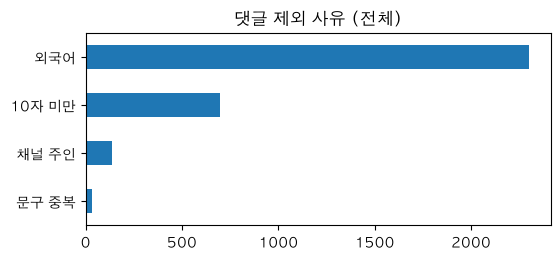

In [2]:
# 최상위·답글별 정제 전후 건수와 제외 사유 합계
stats = pd.read_csv(ROOT / "report" / "evidence" / "clean_stats.csv", encoding="utf-8-sig")
REASON = {"foreign": "외국어", "short": "10자 미만", "owner": "채널 주인", "dup": "문구 중복"}
by_kind = stats.groupby("kind")[["before", "kept"]].sum()
by_kind.loc["합계"] = by_kind.sum()
display(by_kind)
excl = stats[[c for c in REASON if c in stats]].sum().rename(REASON).sort_values()
display(excl.to_frame("제외 수"))
excl.plot.barh(title="댓글 제외 사유 (전체)", figsize=(6, 2.5)); plt.show()

**보인 것**
- 수집 5,457개 중 2,290개(42%)만 남았다. 답글은 2,519 → 548개로 78%가 빠졌고, 최상위 댓글은 41%가 빠졌다.
- 제외 사유 1위는 외국어(2,299개)이고, 2위는 10자 미만(699개)이다.

**한 일**
- 한국어 댓글만 쓰기로 했다. 국내 소비자 반응을 보려는 목적이고, 영어 댓글 처리는 범위 밖이다(기획서 3-4).
- 10자 기준은 `@사용자`와 보이지 않는 공백 문자를 **지운 뒤** 재도록 고쳤다. 지우기 전에는 `@사용자`(한글 3자)가 짧은 답글을 통과시켰다(8판).
- 채널 주인 댓글 137개는 소비자 반응이 아니므로 뺐다. 문구 중복 32개는 최상위 댓글을 먼저 남겼다.
- 이벤트성 댓글은 단어 필터에서 오탐이 5건 나와 버렸다. 대신 "타임스탬프로 시작 + 응원으로 끝남" 패턴만 썼고, 걸린 댓글은 0개였다.
- 답글이 많이 빠지고 말다툼이 섞이기 쉬워서, **예상 등급과 주된 이유는 최상위 댓글로만** 내고 답글은 따로 집계했다.

In [3]:
# 사례·영상별 제외 비율 (외국어가 많은 영상, 채널 주인 답글이 많은 영상 확인)
view = stats.pivot_table(index=["case_id", "video_id"], columns="kind", values=["before", "kept"], aggfunc="sum").fillna(0).astype(int)
view.columns = [f"{k}_{m}" for m, k in view.columns]
view["제외%"] = (1 - view.filter(like="kept").sum(axis=1) / view.filter(like="before").sum(axis=1)).mul(100).round(1)
display(view.sort_values("제외%", ascending=False))

답글_before  최상위_before  답글_kept  최상위_kept   제외%
case_id video_id                                                   
case_10 5Ncuote9ADo       1735        1053      104       206  88.9
case_08 wlz7aUiz6WY        139         201        6       155  52.6
case_02 w8A2ucfqjdM         93         281       40       182  40.6
case_09 XsARMpItpqg         26          43        6        39  34.8
case_05 qrZTpDmZxBk          5          16        5         9  33.3
        vL1F3JJvi78          1          19        1        13  30.0
case_11 Svtv24omXyw         30          44       19        34  28.4
case_06 QW0w2GXe6rA         54         399       38       297  26.0
case_04 Wxrw5sy5_Hk         12          41        9        31  24.5
case_03 8BjqF5fs5SE          4          40        2        32  22.7
case_05 3qWSK7UGBkE          3          21        1        18  20.8
case_07 R92Mba1mTX4        291         500      207       468  14.7
case_01 kJQW_2LHbjU        126         280      110       258   9.4

**보인 것**
- case_10(시프트업)은 88.9%가 빠졌다. 해외 시청자 위주 영상이라 외국어가 대부분이다.
- case_08(우체국)은 52.6%가 빠졌다. 채널이 댓글마다 답글을 단 운영 방식 때문이다(채널 주인 답글 대부분 제외).
- 03·04·05는 남은 최상위 댓글이 32·31·40개(05는 영상 3개 합)로, 기준선 30개에 가까웠다.

**한 일**
- case_10은 수집 상한을 2,000개로 올려 한국어 최상위 206개를 확보했다. 남은 댓글은 게임 팬 집단이라는 한계를 사례 요약과 리포트 9-1에 적었다.
- case_08은 브랜드 답글을 받으려고 우호적인 댓글을 남겼을 수 있어서, 사례 요약 한계로 기록했다.
- 03·04·05는 경계선 사례로 따로 관리했다. 무관 댓글을 뺀 뒤 자격 기준(30개)에 못 미쳐 탈락했다(3절).

## 2. 정제 후 댓글 길이 분포

,count,mean,std,min,25%,50%,75%,max
구분,,,,,,,,
답글,548.0,57.1,83.3,10.0,22.0,36.0,67.0,1483.0
최상위,1742.0,53.0,56.9,10.0,21.0,35.0,63.0,705.0


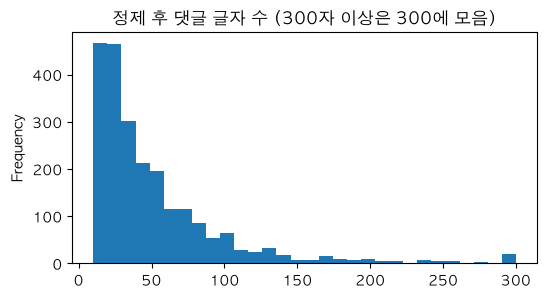

In [4]:
# 남은 댓글(exclude_reason 빈 칸)의 글자 수를 최상위·답글로 나눠 요약
kept = pd.read_sql("""SELECT c.case_id, c.is_reply, length(c.text) AS n_chars
                       FROM youtube_comments c JOIN comment_filter f USING (comment_id)
                       WHERE f.exclude_reason = ''""", con)
kept["구분"] = kept.is_reply.map({0: "최상위", 1: "답글"})
display(kept.groupby("구분").n_chars.describe().round(1))
kept.n_chars.clip(upper=300).plot.hist(bins=30, title="정제 후 댓글 글자 수 (300자 이상은 300에 모음)", figsize=(6, 3)); plt.show()

**보인 것**
- 남은 댓글의 글자 수 중앙값은 최상위 35자, 답글 36자이다. 75%가 63~67자 이하인 짧은 구어체다.
- 가장 긴 댓글은 1,483자(답글)이고, 300자를 넘는 댓글은 소수다.

**한 일 (해석)**
- 댓글 하나만으로는 담긴 정보가 적다. 그래서 청크는 댓글 하나가 아니라 사례·영상 단위로 15개씩 묶었다(6절, 시간순 안 평균 932자).
- 짧은 구어체에서 KURE-v1의 검색 성능은 반응 문항 6개로만 쟀다(Hit@3 1.00). 그래서 리포트에서는 **미검증**으로 둔다.

## 3. 사례별 반응 비율과 영상 종류 (리포트 2-2, GPT 분류 기준)

In [5]:
# 사례 요약의 최상위 댓글 비율 + 영상 종류(뉴스 리포트 / 브랜드 공식)
summ = pd.read_csv(ROOT / "report" / "evidence" / "case_summary.csv", encoding="utf-8-sig")
rows = []
for s in summ.stats.map(json.loads):
    neg = s.get("neg_main") or {}
    rows.append({"case_id": s["case_id"], "자격": s["qualified"], "무관 제외 최상위": s["top_related"],
                 "긍정%": s["pos_pct"], "부정%": s["neg_pct"], "중립%": s["neu_pct"],
                 "부정 주된 이유": neg.get("code"), "동률": neg.get("tie")})
cases = pd.DataFrame(rows)
videos = pd.read_csv(ROOT / "collector" / "case_videos.csv", encoding="utf-8-sig")
kind = videos[videos.use == "Y"].groupby("case_id").video_kind.first()
cases["영상 종류"] = cases.case_id.map(kind)
display(cases)

,case_id,자격,무관 제외 최상위,긍정%,부정%,중립%,부정 주된 이유,동률,영상 종류
0,case_01,1,181,0.6,78.5,21.0,R1,False,뉴스 리포트
1,case_02,1,124,45.2,7.3,47.6,R3,False,브랜드 공식
2,case_03,0,26,65.4,23.1,11.5,G08,True,브랜드 공식
3,case_04,0,26,38.5,50.0,11.5,R3,False,브랜드 공식
4,case_05,0,25,56.0,24.0,20.0,R3,True,브랜드 공식
5,case_06,1,265,81.9,4.9,13.2,G08,False,브랜드 공식
6,case_07,1,460,97.0,0.2,2.8,NaN,None,브랜드 공식
7,case_08,1,123,70.7,4.1,25.2,R3,False,브랜드 공식
8,case_09,1,35,5.7,68.6,25.7,G08,False,뉴스 리포트
9,case_10,1,164,16.5,58.5,25.0,R3,False,브랜드 공식


**보인 것**
- 자격 사례는 7개(01·02·06·07·08·09·10)이다. 03·04·05·11은 무관을 뺀 최상위 댓글이 26·26·25·20개로 기준 30개에 못 미쳤다.
- case_07은 부정이 0.2%뿐이라 주된 이유가 비어 있다(NaN). 부정 댓글이 5개 미만이면 주된 이유를 내지 않는 규칙 때문이다.
- 부정의 주된 이유는 R3(거부감·어색함)이 02·08·10에서 가장 많았다. 06·09는 G08(AI와 무관한 광고 내용 반응)이었다.
- 01은 R1(신뢰 하락) 33.8%와 R4(비용 절감 비판) 32.4%가 거의 같다. 03·05·11은 1·2위가 동률이다.

**한 일**
- 자격 사례가 10개 미만이라 **축소 기준을 적용**했다. "높음" 등급은 쓰지 않고 "관찰됨"과 "근거 부족"만 쓴다. 탈락 사례는 지식베이스에 남기되 예상 근거에서는 뺀다(`qualified = 0`).
- 1·2위가 동률이면 두 이유를 함께 표시하도록 고쳤다(`fix_row_tie`). 2위 이유도 항상 같이 보여 준다.
- G08이 주된 이유인 사례가 있어서, 광고 내용 반응(R8)과 이유 없음(R0)을 G08로 묶어 "AI 때문이 아닌 반응"을 구분했다.

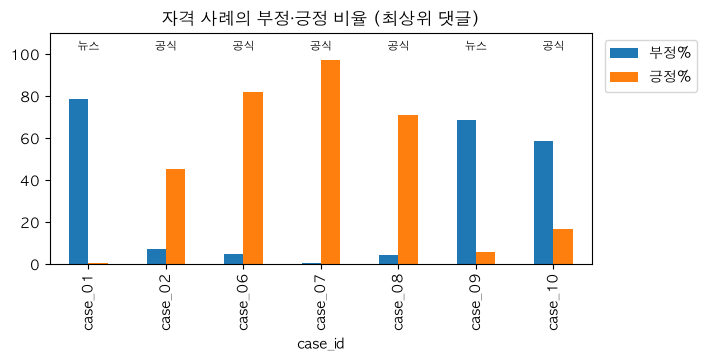

,부정%,긍정%
영상 종류,,
뉴스 리포트,73.6,3.2
브랜드 공식,15.0,62.3


In [6]:
# 자격 사례만: 영상 종류별 부정·긍정 비율
q = cases[cases["자격"] == 1].set_index("case_id")
ax = q[["부정%", "긍정%"]].plot.bar(figsize=(7, 3), title="자격 사례의 부정·긍정 비율 (최상위 댓글)")
for i, k in enumerate(q["영상 종류"]):
    ax.text(i, 102, "뉴스" if k == "뉴스 리포트" else "공식", ha="center", fontsize=8)
ax.set_ylim(0, 110); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()
display(q.groupby("영상 종류")[["부정%", "긍정%"]].mean().round(1))

**보인 것**
- 영상 종류에 따라 반응이 크게 갈린다. 뉴스 리포트 영상(01·09)은 부정 평균 73.6%, 브랜드 공식 영상은 15.0%이다.
- 예외는 case_10이다. 공식 영상인데도 부정이 58.5%로, 게임 팬·해외 시청자 위주라는 특성 때문으로 보인다(추정).

**한 일**
- 비율은 보정하지 않고 그대로 쓴다. 결과를 본 뒤 규칙이나 비율을 바꾸지 않는다는 원칙 때문이다. 대신 청크 메타에 `video_kind`를 남기고, 리포트 9-1에 "뉴스 영상은 논란 시청자, 공식 채널은 홍보·관리로 각각 치우칠 수 있음"을 적었다.
- 화면의 "관찰됨"은 "유튜브 댓글에서 관찰된 반응"이지 소비자 전체의 반응이 아니라고 밝힌다(답변 끝 [주의] 문구).

## 4. 제공 뉴스 탐색 (리포트 2-3)

In [7]:
# 키워드로 거른 후보 696건: 걸린 단어·발행 연도·매체명 결손·URL 중복
cand = pd.read_csv(find("data/interim", "ai_후보기사.csv"), encoding="utf-8-sig")
words = cand["걸린단어"].str.split(",").explode().str.strip().value_counts()
print(f"후보 {len(cand)}건 · 매체명 결손 {cand['매체명'].isna().sum()} · URL 중복 {cand['원문URL'].duplicated().sum()}")
display(words.to_frame("기사 수 (중복 허용)"))
display(pd.to_datetime(cand["발행일"]).dt.year.value_counts().sort_index().to_frame("발행 연도별"))

후보 696건 · 매체명 결손 0 · URL 중복 0


,기사 수 (중복 허용)
걸린단어,
저작권,478
생성 이미지,86
AI 이미지,66
AI 광고,39
가상인간,37
가상인물,2


,발행 연도별
발행일,
2021,1
2022,20
2023,125
2024,133
2025,173
2026,244


**보인 것**
- 키워드로 거른 후보 696건 중 "저작권"으로 걸린 기사가 478건으로 가장 많다. 하지만 본문 앞 200자 기준으로 최소 95건은 방송 기사 끝의 고지문("저작권은 ○○에 있습니다") 때문에 걸렸다(기획서 3-3).
- "생성 이미지"(86건)의 상당수는 사진 설명의 "AI 생성 이미지" 표기 때문에 걸린 주식 기사였다.
- 후보 안에서는 매체명 결손과 URL 중복이 0이다. 원본 묶음 파일(120,057행)에는 URL 중복이 4건 있었다.
- 수작업 검토 결과, 사례 11개를 다룬 기사는 0건이었다.

**한 일**
- 뉴스의 역할을 "사례 반응 근거"에서 **"저작권 쟁점 배경"**으로 좁혔다. 반응 근거는 유튜브 댓글로 직접 수집했다.
- 고지문을 뺀 뒤 본문의 "저작권" 횟수를 세어 기사를 골랐다(다음 표). 방송 고지문은 청크에서도 지웠다.

In [8]:
# 후보 22건 → 최종 16건: 등급별 선정·제외와 제외 이유
short = pd.read_csv(ROOT / "report" / "evidence" / "news_shortlist.csv", encoding="utf-8-sig")
display(pd.crosstab(short.tier, short["최종"], margins=True))
display(short.loc[short["최종"] == "제외", ["tier", "제목", "제외이유"]])

최종,선정,제외,All
tier,,,
A,11,1,12
B,5,3,8
보류,0,2,2
All,16,6,22


,tier,제목,제외이유
7,A,AI가 '지브리풍 뚝딱' 시대에…한국 AI 스타트업은 다죽어 왜?,본문에 저작권 언급 0회(스타트업 경쟁 기사)
16,B,"가상인간에 5,000명 몰렸다…AI 비서에서 창작까지","저작권 언급 1회, 가상인간 소개 위주"
17,B,AI 가상인간으로 돌아온 벤처 대부 혁신의 심장 멈추지 말라,저작권 언급 0회
18,B,"[K-콘텐츠포럼] 안정상 교수 “AI, 콘텐츠 산업의 새로운 문법...","저작권 언급 1회, 산업 전망 위주"
20,보류,[아이온의 AI:온] AI에 '신분증'…워터마크 경쟁,AI 표시 주제 → 범위 밖(1-3)
21,보류,흔적 남겨라 vs 몰래 지워라… 치열해지는 워터마크 시장,AI 표시 주제 → 범위 밖(1-3)


**보인 것**
- 후보 22건 중 16건(A등급 11, B등급 5)을 골랐다.
- 제외한 6건은 두 가지다. 4건은 고지문을 뺀 "저작권" 언급이 0~1회였고, 2건은 워터마크(AI 표시) 기사였다.

**한 일**
- 워터마크 기사는 "AI 생성물 표시 의무 규정은 수집하지 않는다"는 범위(기획서 1-3)와 맞추려고 뺐다. 이 범위 때문에 "가상인물 표시를 해야 하나?" 같은 질문은 답변 불가로 둔다.
- 선정·제외 이유는 이 파일(`report/evidence/news_shortlist.csv`)에 남겨 리포트 2-3의 근거로 쓴다.

## 5. 정부 안내서 쪽별 글자 수 (리포트 4-2 쪽 단위 청킹의 근거)

In [9]:
# 쪽 수, 쪽당 글자 수, 50자 미만 쪽(표지·빈 쪽)
pages = pd.read_sql("SELECT doc_id, page, n_chars FROM gov_pages", con)
s = pages.groupby("doc_id").n_chars.agg(쪽수="count", 평균="mean", 최소="min", 최대="max").round(0)
s["50자 미만 쪽"] = pages[pages.n_chars < 50].groupby("doc_id").size()
display(s.fillna(0).astype(int))

,쪽수,평균,최소,최대,50자 미만 쪽
doc_id,,,,,
gov_01,109,581,0,1684,34
gov_02,82,758,0,1520,9


**보인 것**
- gov_01은 109쪽(평균 581자), gov_02는 82쪽(평균 758자)이다.
- 50자 미만 쪽이 gov_01 34쪽, gov_02 9쪽이고, 0자인 쪽도 있다. 직접 확인해 보니 모두 장 표지·빈 쪽·표지였다. 이미지라서 글이 빠진 본문 쪽은 없었다(기획서 12-1).

**한 일**
- 50자 미만 쪽은 청크에서 뺐다. 300자 미만 쪽은 다음 쪽과 합쳤고, 장이 바뀌면 합치지 않았다.
- 절·질문 단위가 아니라 **쪽 단위**로 잘랐다. pypdf가 글상자 순서로 글을 읽어 질문이 답 뒤에 나오는 쪽이 있었기 때문이다(gov_01 66쪽). 쪽 안에는 질문과 답이 함께 남고, 평가셋 정답도 쪽 번호라 채점과 맞는다.
- 한계: 한 쪽에 Q&A가 여러 개면 한 청크에 섞인다. 목차 쪽(gov_01 5쪽)이 정책 질문 상위에 끼는 문제도 남았다(`exp8_notoc` 후보).

## 6. 적재 결과: 청크 구성 (리포트 4-2)

In [10]:
# 문서 종류·청킹 안별 청크 수와 평균 길이 (Chroma와의 건수 대조는 indexer/check_store.py)
ch = pd.read_sql("SELECT doc_type, scheme, length(text) AS n FROM chunks", con)
t = ch.groupby(["doc_type", "scheme"]).n.agg(청크수="count", 평균글자="mean").round(0).astype(int)
display(t); print("전체 청크:", len(ch))
con.close()

청크수  평균글자
doc_type        scheme           
case_summary    common   11   965
gov             common  139   947
news_provided   common  121   487
youtube_comment reason  171   682
                time    122   932

전체 청크: 564


**보인 것**
- 전체 청크는 564개다. 사례 요약 11, 정부 139, 뉴스 121, 댓글은 이유별 171·시간순 122개다.
- 댓글 두 안 중 이유별 안이 49개 많다. 이유마다 15개씩 끊다 보니 자투리 묶음이 생겼기 때문이다.

**한 일**
- 두 안을 같은 저장소에 함께 넣고, 검색할 때 `scheme`으로 공통(`common`) + 한 안만 골라 쓰게 했다.
- 32문항으로 비교해 Hit@3가 같고(0.594) MRR이 높은 **시간순(time) 안을 채택**했다(0.609 vs 0.587). 그래서 챗봇이 실제로 검색하는 청크는 공통 271 + 시간순 122 = 393개다.
- Chroma 저장 건수와 이 표의 건수가 같은지는 `indexer/check_store.py`로 확인한다.


## 정리: 탐색에서 나온 결정

| 발견 | 결정 | 리포트 |
|---|---|---|
| 외국어·짧은 댓글이 많고, 답글은 78%가 빠짐 | 한국어만 사용, 예상은 최상위 댓글 기준 | 4-1 |
| 자격 사례 7개 (03·04·05·11 탈락) | 축소 기준 적용: "관찰됨"·"근거 부족"만 | 2-2, 9-1 |
| 뉴스 영상은 부정, 공식 영상은 대체로 긍정 (예외 case_10) | 비율은 보정하지 않고 한계로 명시 | 2-2, 9-1 |
| 제공 뉴스에 사례 기사 0건, "저작권"은 고지문으로도 걸림 | 뉴스 역할을 저작권 쟁점으로 좁힘, 반응은 유튜브 댓글로 직접 수집 | 2-3 |
| 정부 PDF의 글 순서가 섞이고 짧은 쪽은 표지·빈 쪽 | 쪽 단위 청킹, 50자 미만 쪽 제외 | 4-2 |
| 댓글 청크 두 안 중 시간순의 MRR이 높음 | 시간순 채택, 검색 대상 393개 | 4-3 |
